# Label Transfer Validation Figure

This notebook reproduces the four-panel validation figure for tile 109 in the Phase 4 2D-to-3D label transfer workflow. It uses the original 2D structure mask, the initial projected LiDAR labels, and the refined LiDAR labels after voxel and polar refinement.

In [22]:
from pathlib import Path
import sys

from IPython.display import Image, display


def find_repo_root(start: Path) -> Path:
    script_relpath = Path('phase_4_3D_lidar_prep/step_3_structure_class/make_label_transfer_validation_figure.py')
    for candidate in [start, *start.parents]:
        if (candidate / script_relpath).exists():
            return candidate
    raise FileNotFoundError(f'Could not locate repository root from {start}')


repo_root = find_repo_root(Path.cwd().resolve())
script_dir = repo_root / 'phase_4_3D_lidar_prep' / 'step_3_structure_class'
if str(script_dir) not in sys.path:
    sys.path.insert(0, str(script_dir))

from make_label_transfer_validation_figure import make_label_transfer_validation_figure

In [2]:
mask_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/masks/tiles_3072/raw/structure_class/annotation_raster/downsample_5cm_nearest/mask_structure_3072.109.tif')
projected_las_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/mask/coreg/icp/mask_tiles_multispectral.109.las')
refined_las_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_109.las')
output_path = Path('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_tile109.png')

mask_path, projected_las_path, refined_las_path, output_path

(PosixPath('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/masks/tiles_3072/raw/structure_class/annotation_raster/downsample_5cm_nearest/mask_structure_3072.109.tif'),
 PosixPath('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/mask/coreg/icp/mask_tiles_multispectral.109.las'),
 PosixPath('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_109.las'),
 PosixPath('/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_tile109.png'))

In [23]:
make_label_transfer_validation_figure(
    mask_path=str(mask_path),
    projected_las_path=str(projected_las_path),
    refined_las_path=str(refined_las_path),
    output_path=str(output_path),
    class_codes=(64, 65, 66, 67, 68),
    max_points=150_000,
    point_size=0.5,
    show_background_mask=False,
    sample_seed=42,
)

print(output_path)
print(f'Exists: {output_path.exists()}')

/media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/lidar/clipped/validation/label_transfer_validation_tile109.png
Exists: True


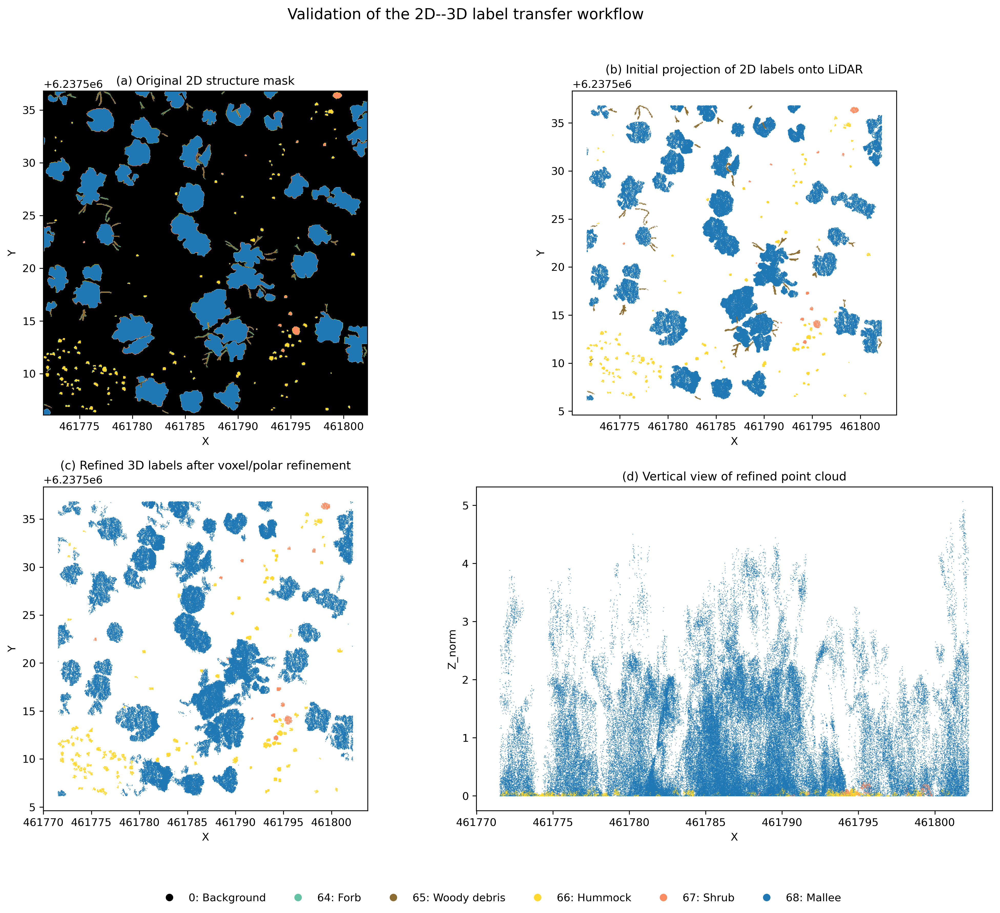

In [24]:
display(Image(filename=str(output_path)))

## Multispectral Overlay QC

These cells add the same kind of imagery-plus-LiDAR visual check used in the clipping and ICP registration notebooks. They try to locate the matching multispectral tile for tile 109 automatically and fall back to the structure-mask raster if a multispectral TIFF is not available on this disk.

In [25]:
import re
from pathlib import Path

import laspy
import matplotlib.pyplot as plt
import numpy as np
import rasterio

OVERLAY_CLASS_COLORS = {
    64: '#66c2a5',
    65: '#8c6d31',
    66: '#ffd92f',
    67: '#fc8d62',
    68: '#1f78b4',
}

OVERLAY_CLASS_LABELS = {
    64: 'Forb',
    65: 'Woody debris',
    66: 'Hummock',
    67: 'Shrub',
    68: 'Mallee',
}


def find_site_root(path: Path) -> Path:
    for candidate in [path, *path.parents]:
        if candidate.name.startswith('site'):
            return candidate
    raise FileNotFoundError(f'Could not infer site root from {path}')



def detect_tile_id(*paths: Path) -> str:
    for path in paths:
        match = re.search(r'(\d+)$', path.stem)
        if match:
            return match.group(1)
    raise ValueError('Could not detect tile id from the configured paths')



def find_multispectral_raster(site_root: Path, tile_id: str) -> Path | None:
    candidates = [
        site_root / 'imagery' / 'inputs' / 'predictors' / 'tiles_3072' / 'stacked' / f'tiles_multispectral.{tile_id}.tif',
        site_root / 'imagery' / 'clipped' / 'raster' / f'tiles_multispectral.{tile_id}.tif',
        site_root / 'imagery' / 'clipped' / 'raster' / 'new' / f'tiles_multispectral.{tile_id}.tif',
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate

    imagery_root = site_root / 'imagery'
    if not imagery_root.exists():
        return None

    preferred = []
    fallback = []
    for path in imagery_root.rglob(f'*{tile_id}*.tif'):
        path_str = str(path).lower()
        if 'multispectral' in path_str and 'mask' not in path_str:
            preferred.append(path)
        elif 'mask' not in path_str:
            fallback.append(path)
    matches = sorted(preferred) or sorted(fallback)
    return matches[0] if matches else None



def normalize_band(band: np.ndarray) -> np.ndarray:
    finite = band[np.isfinite(band)]
    if finite.size == 0:
        return np.zeros_like(band, dtype=np.float32)
    lo, hi = np.percentile(finite, [2, 98])
    scaled = np.clip((band - lo) / (hi - lo + 1e-6), 0, 1)
    scaled[~np.isfinite(scaled)] = 0
    return scaled.astype(np.float32)



def load_raster_rgb(raster_path: Path) -> tuple[np.ndarray, tuple[float, float, float, float], tuple[int, ...]]:
    with rasterio.open(raster_path) as src:
        if src.count >= 5:
            bands = (5, 3, 1)
            rgb = np.stack([normalize_band(src.read(b)) for b in bands], axis=-1)
        elif src.count >= 3:
            bands = (1, 2, 3)
            rgb = np.stack([normalize_band(src.read(b)) for b in bands], axis=-1)
        else:
            bands = (1,)
            gray = normalize_band(src.read(1))
            rgb = np.stack([gray, gray, gray], axis=-1)
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
    return rgb, extent, bands



def load_class_overlay_points(las_path: Path, max_points: int = 200_000, seed: int = 42) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    las = laspy.read(las_path)
    x = np.asarray(las.x)
    y = np.asarray(las.y)
    classification = np.asarray(las.classification)

    keep = np.isin(classification, list(OVERLAY_CLASS_COLORS))
    x = x[keep]
    y = y[keep]
    classification = classification[keep]

    if len(x) > max_points:
        rng = np.random.default_rng(seed)
        idx = rng.choice(len(x), size=max_points, replace=False)
        x = x[idx]
        y = y[idx]
        classification = classification[idx]

    colors = np.array([OVERLAY_CLASS_COLORS[int(code)] for code in classification], dtype=object)
    return x, y, colors



tile_id = detect_tile_id(mask_path, projected_las_path, refined_las_path)
site_root = find_site_root(mask_path)
multispectral_raster_path = find_multispectral_raster(site_root, tile_id)
overlay_raster_path = multispectral_raster_path if multispectral_raster_path is not None else mask_path

rgb_overlay, overlay_extent, overlay_bands = load_raster_rgb(overlay_raster_path)

print(f'Tile id: {tile_id}')
print(f'Site root: {site_root}')
if multispectral_raster_path is None:
    print('No multispectral TIFF was found automatically; using the mask raster as the overlay background.')
else:
    print(f'Multispectral raster: {multispectral_raster_path}')
print(f'Overlay raster: {overlay_raster_path}')
print(f'Bands used for display: {overlay_bands}')

Tile id: 109
Site root: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001
No multispectral TIFF was found automatically; using the mask raster as the overlay background.
Overlay raster: /media/laura/8402326D023263F8/calperumResearch/site1_1_DD0001/inputs/masks/tiles_3072/raw/structure_class/annotation_raster/downsample_5cm_nearest/mask_structure_3072.109.tif
Bands used for display: (1,)


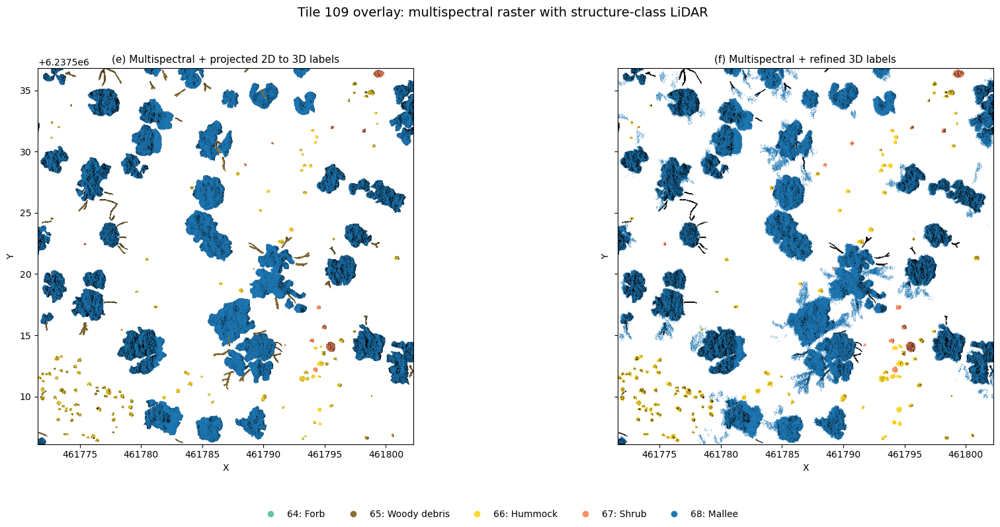

Projected overlay points: 200,000
Refined overlay points: 200,000


In [26]:
projected_x, projected_y, projected_colors = load_class_overlay_points(projected_las_path)
refined_x, refined_y, refined_colors = load_class_overlay_points(refined_las_path)

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharex=True, sharey=True)

for ax, xvals, yvals, color_vals, title in [
    (axes[0], projected_x, projected_y, projected_colors, '(e) Multispectral + projected 2D to 3D labels'),
    (axes[1], refined_x, refined_y, refined_colors, '(f) Multispectral + refined 3D labels'),
]:
    ax.imshow(rgb_overlay, extent=overlay_extent, origin='upper')
    ax.scatter(xvals, yvals, s=0.6, c=color_vals, alpha=0.65, linewidths=0)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_xlim(overlay_extent[0], overlay_extent[1])
    ax.set_ylim(overlay_extent[2], overlay_extent[3])
    ax.set_aspect('equal')

legend_handles = [
    plt.Line2D(
        [0],
        [0],
        marker='o',
        color='w',
        markerfacecolor=color,
        markersize=8,
        linestyle='None',
        label=f'{code}: {OVERLAY_CLASS_LABELS[code]}',
    )
    for code, color in OVERLAY_CLASS_COLORS.items()
]
fig.legend(handles=legend_handles, loc='lower center', ncol=5, frameon=False)
fig.suptitle(f'Tile {tile_id} overlay: multispectral raster with structure-class LiDAR', fontsize=14, y=0.98)
fig.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.show()

print(f'Projected overlay points: {len(projected_x):,}')
print(f'Refined overlay points: {len(refined_x):,}')

## Interactive 3D View

This section uses Plotly for a BedMachine-inspired interactive 3D display. The LiDAR points are gridded into a local HAG surface and the class-coloured points are overlaid on top, so the scene reads more like a terrain model while still preserving the structure labels.

In [27]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from make_label_transfer_validation_figure import filter_points_by_class, read_las_points, sample_points


PLOTLY_CLASS_CODES = (64, 65, 66, 67, 68)
PLOTLY_MAX_POINTS = 175_000
PLOTLY_CAMERA = dict(eye=dict(x=1.7, y=1.7, z=0.7))



def prepare_plotly_cloud(las_path: Path, max_points: int = PLOTLY_MAX_POINTS) -> dict[str, np.ndarray | None]:
    points = read_las_points(str(las_path))
    points = filter_points_by_class(points, PLOTLY_CLASS_CODES)
    points = sample_points(points, max_points=max_points, seed=42)
    return points



def height_values(points: dict[str, np.ndarray | None]) -> np.ndarray:
    z_norm = points.get('z_norm')
    if z_norm is not None:
        return np.asarray(z_norm)
    return np.asarray(points['z'])



def add_cloud_traces(fig, points: dict[str, np.ndarray | None], col: int, title: str, show_legend: bool) -> None:
    zvals = height_values(points)
    for class_code in PLOTLY_CLASS_CODES:
        class_mask = points['class'] == class_code
        if not np.any(class_mask):
            continue
        fig.add_trace(
            go.Scatter3d(
                x=points['x'][class_mask],
                y=points['y'][class_mask],
                z=zvals[class_mask],
                mode='markers',
                name=f'{class_code}: {OVERLAY_CLASS_LABELS[class_code]}',
                legendgroup=str(class_code),
                showlegend=show_legend,
                marker=dict(
                    size=1.7,
                    color=OVERLAY_CLASS_COLORS[class_code],
                    opacity=0.72,
                ),
                hovertemplate=(
                    'Class: ' + OVERLAY_CLASS_LABELS[class_code] + '<br>' +
                    'X: %{x:.2f}<br>' +
                    'Y: %{y:.2f}<br>' +
                    'HAG/Z: %{z:.2f}<extra></extra>'
                ),
            ),
            row=1,
            col=col,
        )


projected_plotly = prepare_plotly_cloud(projected_las_path)
refined_plotly = prepare_plotly_cloud(refined_las_path)

fig = make_subplots(
    rows=1,
    cols=2,
    specs=[[{'type': 'scene'}, {'type': 'scene'}]],
    subplot_titles=(
        'Projected 2D to 3D labels',
        'Refined 3D labels',
    ),
)

add_cloud_traces(fig, projected_plotly, col=1, title='Projected 2D to 3D labels', show_legend=True)
add_cloud_traces(fig, refined_plotly, col=2, title='Refined 3D labels', show_legend=False)

scene_style = dict(
    xaxis=dict(title='X', backgroundcolor='rgb(245,245,245)', gridcolor='white', showbackground=True),
    yaxis=dict(title='Y', backgroundcolor='rgb(245,245,245)', gridcolor='white', showbackground=True),
    zaxis=dict(title='HAG / Z', backgroundcolor='rgb(235,241,245)', gridcolor='white', showbackground=True),
    aspectmode='data',
    camera=PLOTLY_CAMERA,
)

fig.update_layout(
    title=f'Interactive 3D label-transfer view for tile {tile_id}',
    template='plotly_white',
    height=760,
    width=1500,
    margin=dict(l=0, r=0, t=60, b=0),
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='left', x=0.0),
    scene=scene_style,
    scene2=scene_style,
)

fig.show()

print(f'Projected 3D points: {len(projected_plotly["x"]):,}')
print(f'Refined 3D points: {len(refined_plotly["x"]):,}')

Projected 3D points: 175,000
Refined 3D points: 175,000


## Surface-Style 3D View

This view uses the refined classified LAS file at `znorm_3Dlabels_109.las`. The surface height is derived from the refined cloud, and each surface cell is coloured by its dominant structure class so the 3D view shows both shape and label pattern.

In [28]:
from scipy.ndimage import gaussian_filter
from scipy.stats import binned_statistic_2d

SURFACE_BINS = 120
SURFACE_SMOOTH_SIGMA = 1.1
SURFACE_CAMERA = dict(eye=dict(x=1.55, y=-1.75, z=1.05))
SURFACE_COLORSCALE = [
    [0.00, '#16132e'],
    [0.25, '#223b78'],
    [0.55, '#4f8fc2'],
    [0.82, '#7fc4d7'],
    [1.00, '#d9f3f8'],
]


def build_smooth_surface(points: dict[str, np.ndarray | None], bins: int = SURFACE_BINS) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    xvals = np.asarray(points['x'])
    yvals = np.asarray(points['y'])
    zvals = height_values(points)

    z_mean, x_edges, y_edges, _ = binned_statistic_2d(
        xvals,
        yvals,
        zvals,
        statistic='mean',
        bins=bins,
    )

    z_surface = z_mean.T
    valid = np.isfinite(z_surface)
    smooth_values = gaussian_filter(np.where(valid, z_surface, 0.0), sigma=SURFACE_SMOOTH_SIGMA)
    smooth_weights = gaussian_filter(valid.astype(np.float32), sigma=SURFACE_SMOOTH_SIGMA)
    z_surface = np.where(smooth_weights > 0, smooth_values / np.maximum(smooth_weights, 1e-6), np.nan)

    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
    x_grid, y_grid = np.meshgrid(x_centers, y_centers)
    return x_grid, y_grid, z_surface


refined_surface_points = read_las_points(str(refined_las_path))
refined_surface_x, refined_surface_y, refined_surface_z = build_smooth_surface(refined_surface_points)

surface_fig = go.Figure(
    data=[
        go.Surface(
            x=refined_surface_x,
            y=refined_surface_y,
            z=refined_surface_z,
            surfacecolor=refined_surface_z,
            colorscale=SURFACE_COLORSCALE,
            showscale=True,
            opacity=1.0,
            colorbar=dict(title='Surface elevation', len=0.82, thickness=18),
            contours=dict(
                z=dict(show=True, usecolormap=False, color='rgba(255,255,255,0.35)', width=1),
            ),
            hovertemplate='X: %{x:.2f}<br>Y: %{y:.2f}<br>Surface elevation: %{z:.2f}<extra></extra>',
        )
    ]
)

surface_fig.update_layout(
    title=f'Refined surface model for tile {tile_id}',
    template='plotly_white',
    width=900,
    height=560,
    margin=dict(l=0, r=0, t=50, b=0),
    scene=dict(
        xaxis=dict(title='X coordinate', showbackground=False, gridcolor='rgba(180,200,220,0.45)'),
        yaxis=dict(title='Y coordinate', showbackground=False, gridcolor='rgba(180,200,220,0.45)'),
        zaxis=dict(title='Surface elevation', showbackground=False, gridcolor='rgba(180,200,220,0.45)'),
        aspectmode='manual',
        aspectratio=dict(x=1.0, y=1.0, z=0.55),
        camera=SURFACE_CAMERA,
    ),
)

surface_fig.show()

print(f'Surface grid shape: {refined_surface_z.shape[0]} rows x {refined_surface_z.shape[1]} columns')
print(f'Surface elevation range: {np.nanmin(refined_surface_z):.2f} to {np.nanmax(refined_surface_z):.2f}')

Surface grid shape: 120 rows x 120 columns
Surface elevation range: 0.00 to 4.20
